# Environment & Dependency Setup
Run this cell if running in a fresh Jupyter environment to install required visualization and data dependencies.

In [2]:
!pip install numpy opencv-python matplotlib pandas

  Using cached numpy-2.5.1-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached matplotlib-3.11.1-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.3.3-cp312-cp312-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.63.0-cp312-cp312-win_amd64.whl.metadata (121 kB)
  Using cached kiwisolver-1.5.0-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
  Using cached tzdata-2026.3-py2.py3-none-any.whl.metadata (1.4 kB)
Using cached numpy-2.5.1-cp312-cp312-win_amd64.whl (12.4 MB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Using cached matplotlib-3.11.1-cp312-cp312-win_amd64.whl (9.3 MB)
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   - -----


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# COCO Dataset Summary
Inspect image distributions, bounding box counts, and category definitions across splits.

In [3]:
import json
import random
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path

dataset_dir = Path("../dataset_coco")
splits = ["train", "val", "test"]
total_img = 0
total_ann = 0

print(f"=== DATASET: {dataset_dir.name} ===")
for split in splits:
    fpath = dataset_dir / "annotations" / f"instances_{split}.json"
    if not fpath.exists():
        continue
    with open(fpath, 'r') as f:
        d = json.load(f)
    imgs = len(d['images'])
    anns = len(d['annotations'])
    classes = len(d['categories'])
    total_img += imgs
    total_ann += anns
    print(f"[{split.upper()}] -> Images: {imgs}, Annotations: {anns}, Classes: {classes}")

print("----------------------")
print(f"OVERALL TOTALS -> Images: {total_img}, Annotations: {total_ann}")


=== DATASET: dataset_coco_full ===
[TRAIN] -> Foto: 836, Anotasi: 10085, Class: 1
[VAL] -> Foto: 179, Anotasi: 2147, Class: 1
[TEST] -> Foto: 180, Anotasi: 2085, Class: 1
----------------------
TOTAL KESELURUHAN -> Foto: 1195, Anotasi: 14317


## Visualizing Sample Annotations
Displays random sample images with annotated bounding boxes from the chosen dataset split.

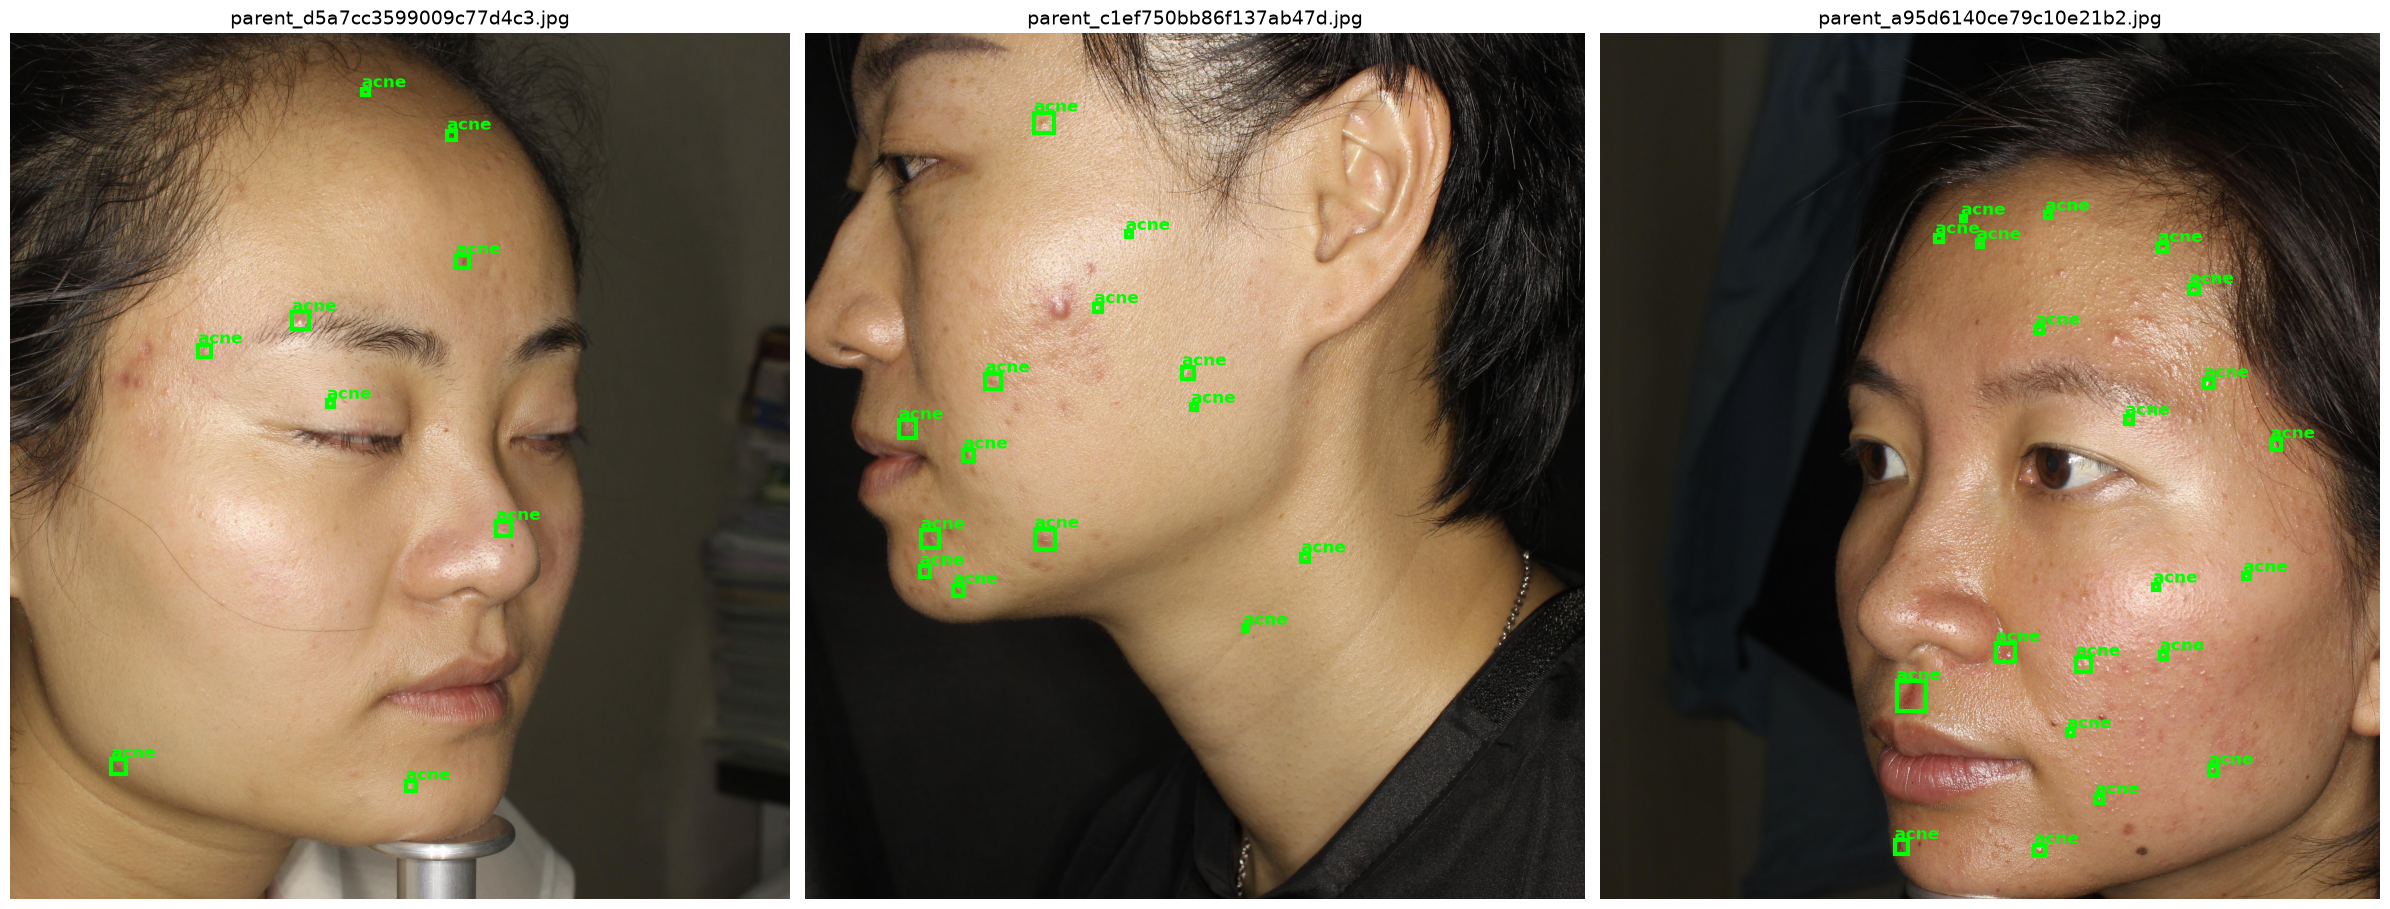

In [4]:
def visualize_samples(dataset_path, split="train", num_samples=3):
    anno_file = dataset_path / "annotations" / f"instances_{split}.json"
    if not anno_file.exists():
        print("Annotation file not found.")
        return
        
    with open(anno_file, 'r') as f:
        coco = json.load(f)
        
    images_dict = {img['id']: img for img in coco['images']}
    anns_dict = {}
    for ann in coco['annotations']:
        img_id = ann['image_id']
        if img_id not in anns_dict:
            anns_dict[img_id] = []
        anns_dict[img_id].append(ann)
        
    img_ids = list(images_dict.keys())
    sample_ids = random.sample(img_ids, min(num_samples, len(img_ids)))
    
    fig, axes = plt.subplots(1, len(sample_ids), figsize=(24, 10))
    if num_samples == 1:
        axes = [axes]
        
    for i, img_id in enumerate(sample_ids):
        img_info = images_dict[img_id]
        img_path = dataset_path / split / img_info['file_name']
        
        img = cv2.imread(str(img_path))
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            axes[i].imshow(img)
        else:
            print(f"Image could not be loaded: {img_path}")
            
        axes[i].set_title(img_info['file_name'], fontsize=14)
        axes[i].axis('off')
        
        # Draw bounding boxes
        if img_id in anns_dict:
            for ann in anns_dict[img_id]:
                x, y, w, h = ann['bbox']
                rect = patches.Rectangle((x, y), w, h, linewidth=3, edgecolor='lime', facecolor='none')
                axes[i].add_patch(rect)
                axes[i].text(x, max(0, y - 5), "acne", color='lime', fontsize=12, weight='bold')
                
    plt.tight_layout()
    plt.show()

# Display 3 random training samples
visualize_samples(dataset_dir, "train", 3)
